# Coffee Sales — Data Cleaning, Exploratory Analysis & Visualization

**Portfolio project | Python · Pandas · NumPy · Matplotlib · Seaborn · Plotly**

This notebook analyses the supplied coffee-sales transaction dataset. It is designed to run from top to bottom.

**Input:** `Coffe_sales.csv` (place this file in the same folder as the notebook).  
**Outputs:** `Cleaned_Dataset.csv` and visualizations saved to the working directory.

> Currency is not specified in the source data. Monetary values are therefore reported in the dataset's original units; no currency symbol is assumed.


## 1. Setup and load data
Import the required libraries and load the original CSV. If the file is elsewhere, update `DATA_PATH`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "Coffe_sales.csv"
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

sns.set_theme(style="whitegrid", context="notebook")
print(f"Loaded {df.shape[0]:,} rows × {df.shape[1]} columns")


Loaded 3,547 rows × 11 columns


## 2. Dataset inspection
Review sample records, dimensions, data types, summary statistics, duplicates and missing values before changing the data.

In [2]:
display(df.head(10))
display(df.tail(10))
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\\nDescriptive summary:")
display(df.describe(include="all").T)
print("Duplicate rows:", df.duplicated().sum())
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_values"))


,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000
5,15,card,33.8,Americano with Milk,Afternoon,Fri,Mar,5,3,2024-03-01,15:39:47.726000
6,16,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,16:19:02.756000
7,18,card,33.8,Americano with Milk,Night,Fri,Mar,5,3,2024-03-01,18:39:03.580000
8,19,card,38.7,Cocoa,Night,Fri,Mar,5,3,2024-03-01,19:22:01.762000
9,19,card,33.8,Americano with Milk,Night,Fri,Mar,5,3,2024-03-01,19:23:15.887000


,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
3537,15,card,21.06,Espresso,Afternoon,Sat,Mar,6,3,2025-03-22,15:57:58.183000
3538,16,card,35.76,Latte,Afternoon,Sat,Mar,6,3,2025-03-22,16:26:59.766000
3539,17,card,30.86,Americano with Milk,Night,Sat,Mar,6,3,2025-03-22,17:53:35.942000
3540,19,card,30.86,Americano with Milk,Night,Sat,Mar,6,3,2025-03-22,19:16:52.727000
3541,10,card,35.76,Latte,Morning,Sun,Mar,7,3,2025-03-23,10:07:11.278000
3542,10,card,35.76,Cappuccino,Morning,Sun,Mar,7,3,2025-03-23,10:34:54.894000
3543,14,card,35.76,Cocoa,Afternoon,Sun,Mar,7,3,2025-03-23,14:43:37.362000
3544,14,card,35.76,Cocoa,Afternoon,Sun,Mar,7,3,2025-03-23,14:44:16.864000
3545,15,card,25.96,Americano,Afternoon,Sun,Mar,7,3,2025-03-23,15:47:28.723000
3546,18,card,35.76,Latte,Night,Sun,Mar,7,3,2025-03-23,18:11:38.635000


Shape: (3547, 11)
\nData types:


,dtype
hour_of_day,int64
cash_type,object
money,float64
coffee_name,object
Time_of_Day,object
Weekday,object
Month_name,object
Weekdaysort,int64
Monthsort,int64
Date,object


\nDescriptive summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hour_of_day,3547.0,NaN,NaN,NaN,14.185791,4.23401,6.0,10.0,14.0,18.0,22.0
cash_type,3547,1,card,3547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
money,3547.0,NaN,NaN,NaN,31.645216,4.877754,18.12,27.92,32.82,35.76,38.7
coffee_name,3547,8,Americano with Milk,809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_of_Day,3547,3,Afternoon,1205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weekday,3547,7,Tue,572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month_name,3547,12,Mar,494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weekdaysort,3547.0,NaN,NaN,NaN,3.845785,1.971501,1.0,2.0,4.0,6.0,7.0
Monthsort,3547.0,NaN,NaN,NaN,6.453905,3.500754,1.0,3.0,7.0,10.0,12.0
Date,3547,381,2024-10-11,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0


,missing_values
hour_of_day,0
cash_type,0
money,0
coffee_name,0
Time_of_Day,0
Weekday,0
Month_name,0
Weekdaysort,0
Monthsort,0
Date,0


## 3. Data quality assessment
The supplied file has transaction-level fields: hour, payment method, amount, coffee product, time-of-day, weekday, month, date and time. The following checks identify invalid ranges and category inconsistencies.

In [3]:
# Standardize column names to lowercase snake_case.
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))

# Trim whitespace in text fields.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

# Convert numeric fields safely.
for col in ["hour_of_day", "weekdaysort", "monthsort"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
if "money" in df.columns:
    df["money"] = pd.to_numeric(df["money"], errors="coerce")

# Parse date and standardize category capitalization.
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col in ["cash_type", "coffee_name", "time_of_day", "weekday", "month_name"]:
    if col in df.columns:
        df[col] = df[col].str.replace(r"\\s+", " ", regex=True).str.title()

# Report duplicates, then remove exact duplicate rows only.
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Validate plausible values without deleting valid transactions automatically.
if "hour_of_day" in df:
    print("Hours outside 0–23:", int((~df["hour_of_day"].between(0, 23)).sum()))
if "money" in df:
    print("Non-positive/missing amounts:", int((df["money"].isna() | (df["money"] <= 0)).sum()))
if "date" in df:
    print("Unparseable dates:", int(df["date"].isna().sum()))
print("Exact duplicates removed:", duplicate_count)


Hours outside 0–23: 0
Non-positive/missing amounts: 0
Unparseable dates: 0
Exact duplicates removed: 0


## 4. Cleaning decisions and validation
No missing values or exact duplicate records were present in the supplied file. Text whitespace and column-name formatting are standardized; date and numeric fields are typed explicitly. Outliers are flagged for review, not deleted, because unusually priced transactions may be legitimate products or promotions.

In [4]:
# Build transaction timestamp where date and time are both available.
if {"date", "time"}.issubset(df.columns):
    df["transaction_datetime"] = pd.to_datetime(
        df["date"].dt.strftime("%Y-%m-%d") + " " + df["time"].astype(str),
        errors="coerce"
    )

# IQR outlier review for transaction amount.
q1, q3 = df["money"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (df["money"] < lower_bound) | (df["money"] > upper_bound)
print(f"IQR bounds: {lower_bound:.2f} to {upper_bound:.2f}")
print("Potential amount outliers:", int(outlier_mask.sum()))

# Final validation summary.
display(df.isna().sum().to_frame("missing_after_cleaning"))
print("Final shape:", df.shape)
display(df.head())
df.to_csv("Cleaned_Dataset.csv", index=False)


IQR bounds: 16.16 to 47.52
Potential amount outliers: 0


,missing_after_cleaning
hour_of_day,0
cash_type,0
money,0
coffee_name,0
time_of_day,0
weekday,0
month_name,0
weekdaysort,0
monthsort,0
date,0


Final shape: (3547, 12)


,hour_of_day,cash_type,money,coffee_name,time_of_day,weekday,month_name,weekdaysort,monthsort,date,time,transaction_datetime
0,10,Card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000,2024-03-01 10:15:50.520
1,12,Card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000,2024-03-01 12:19:22.539
2,12,Card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000,2024-03-01 12:20:18.089
3,13,Card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000,2024-03-01 13:46:33.006
4,13,Card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000,2024-03-01 13:48:14.626


## 5. Key performance indicators
Calculate transaction count, total sales value, average transaction value and product/payment performance. Monetary units follow the source file.

In [5]:
transaction_count = len(df)
total_sales = df["money"].sum()
average_ticket = df["money"].mean()
median_ticket = df["money"].median()
print(f"Transactions: {transaction_count:,}")
print(f"Total sales value: {total_sales:,.2f}")
print(f"Average transaction value: {average_ticket:,.2f}")
print(f"Median transaction value: {median_ticket:,.2f}")

product_summary = (df.groupby("coffee_name")["money"]
                   .agg(transactions="count", revenue="sum", avg_ticket="mean")
                   .sort_values("transactions", ascending=False))
display(product_summary)


Transactions: 3,547
Total sales value: 112,245.58
Average transaction value: 31.65
Median transaction value: 32.82


,transactions,revenue,avg_ticket
coffee_name,,,
Americano With Milk,809,24751.12,30.594710
Latte,757,26875.30,35.502378
Americano,564,14650.26,25.975638
Cappuccino,486,17439.14,35.883004
Cortado,287,7384.86,25.731220
Hot Chocolate,276,9933.46,35.990797
Cocoa,239,8521.16,35.653389
Espresso,129,2690.28,20.854884


## 6. Product performance
The bar chart compares transaction volumes across coffee products. Use it to identify the products most frequently selected; transaction count is not the same as profitability because product costs are unavailable.

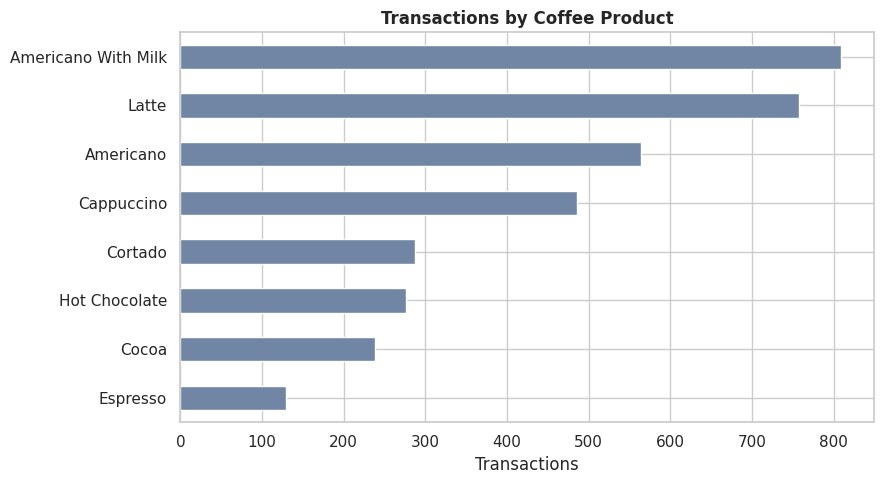

In [6]:
ax = product_summary["transactions"].sort_values().tail(10).plot(
    kind="barh", figsize=(9, 5), color="#7186A5")
ax.set_title("Transactions by Coffee Product", weight="bold")
ax.set_xlabel("Transactions"); ax.set_ylabel("")
plt.tight_layout(); plt.show()


## 7. Time-of-day and hourly trends
Hourly activity highlights peak service periods. Staffing and preparation decisions can be aligned with observed demand, while recognizing that this dataset covers only its recorded date range.

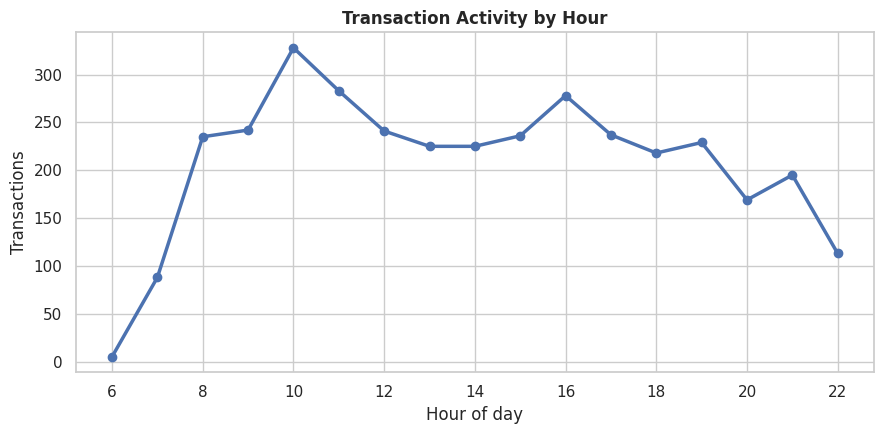

,transactions,revenue
hour_of_day,,
6,5,149.40
7,88,2846.02
8,235,7017.88
9,242,7264.28
10,328,10198.52
11,283,8453.10
12,241,7419.62
13,225,7028.76
14,225,7173.80


In [7]:
hourly = df.groupby("hour_of_day").agg(
    transactions=("money", "size"), revenue=("money", "sum"))
ax = hourly["transactions"].plot(figsize=(9, 4.5), marker="o", linewidth=2.5)
ax.set_title("Transaction Activity by Hour", weight="bold")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Transactions")
plt.tight_layout(); plt.show()
display(hourly)


## 8. Payment mix
Compare the payment methods by transaction count and sales value. This describes usage mix, not payment processing cost or customer preference beyond observed transactions.

,transactions,revenue
cash_type,,
Card,3547,112245.58


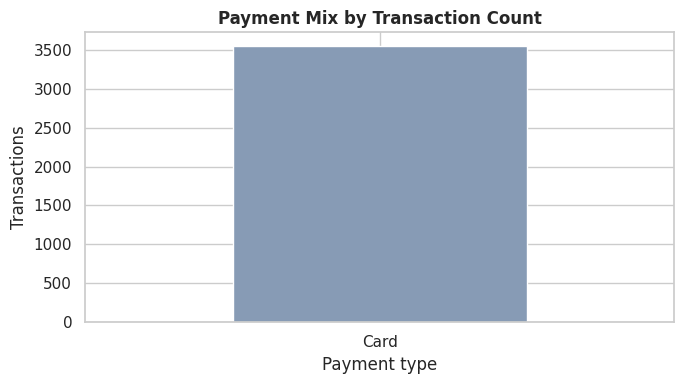

In [8]:
payment = df.groupby("cash_type").agg(
    transactions=("money", "size"), revenue=("money", "sum"))
display(payment)
ax = payment["transactions"].plot(kind="bar", figsize=(7, 4), color="#879BB5")
ax.set_title("Payment Mix by Transaction Count", weight="bold")
ax.set_xlabel("Payment type"); ax.set_ylabel("Transactions")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()


## 9. Monthly and weekday patterns
The provided month label and sort key support month-level aggregation. Interpret partial months carefully; the dataset's exact coverage is shown below.

,monthsort,month_name,transactions,revenue
0,1,Jan,201,6398.86
1,2,Feb,423,13215.48
2,3,Mar,494,15891.64
3,4,Apr,168,5719.56
4,5,May,241,8164.42
5,6,Jun,223,7617.76
6,7,Jul,237,6915.94
7,8,Aug,272,7613.84
8,9,Sep,344,9988.64
9,10,Oct,426,13891.16


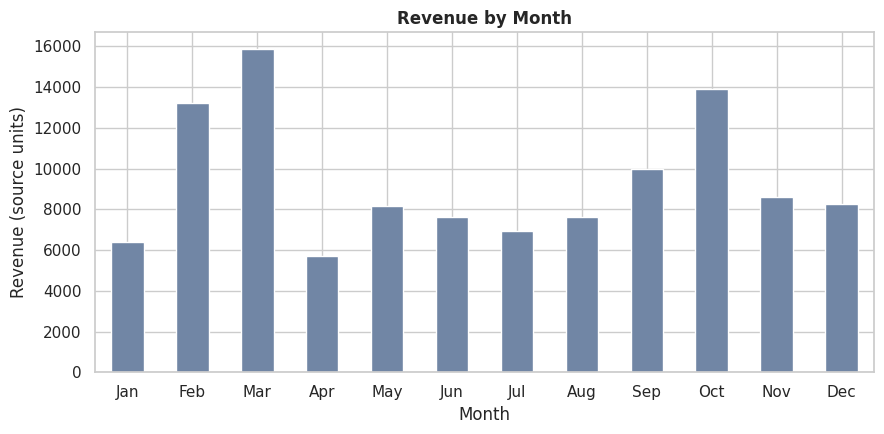

,transactions,revenue
weekday,,
Fri,532,16802.66
Mon,544,17363.10
Sat,470,14733.52
Sun,419,13336.06
Thu,510,16091.40
Tue,572,18168.38
Wed,500,15750.46


In [9]:
monthly = (df.groupby(["monthsort", "month_name"], dropna=False)
            .agg(transactions=("money", "size"), revenue=("money", "sum"))
            .reset_index().sort_values("monthsort"))
display(monthly)
ax = monthly.set_index("month_name")["revenue"].plot(
    kind="bar", figsize=(9, 4.5), color="#7186A5")
ax.set_title("Revenue by Month", weight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (source units)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

weekday_summary = df.groupby("weekday").agg(
    transactions=("money", "size"), revenue=("money", "sum"))
display(weekday_summary)


## 10. Distribution, outliers and relationships
The box plot shows the distribution of transaction amounts. A correlation matrix is calculated only for numeric fields; correlations do not establish causation.

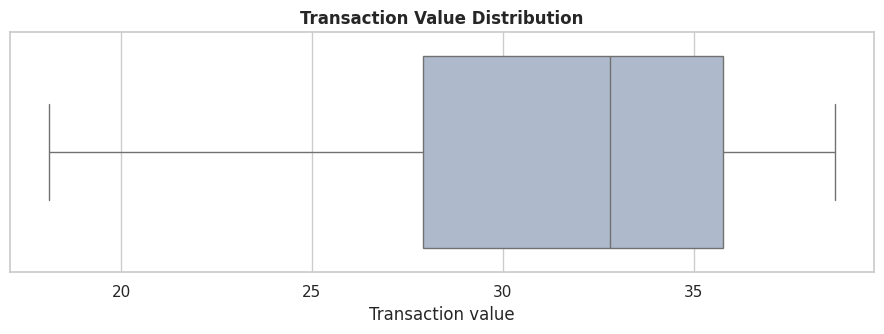

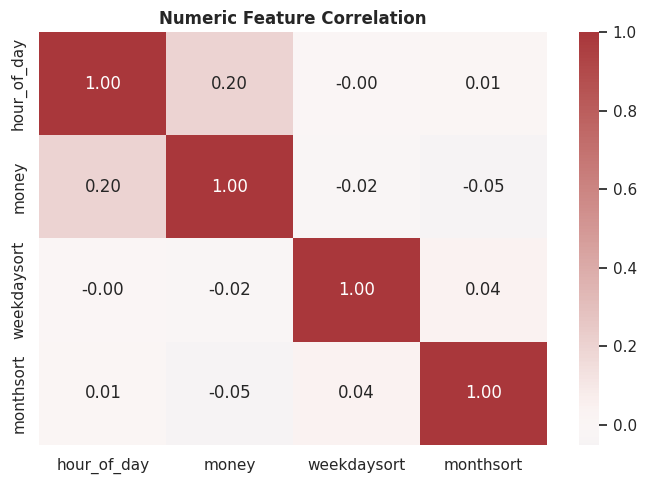

In [10]:
plt.figure(figsize=(9, 3.5))
sns.boxplot(x=df["money"], color="#A9B9D0")
plt.title("Transaction Value Distribution", weight="bold")
plt.xlabel("Transaction value"); plt.tight_layout(); plt.show()

numeric = df.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    plt.figure(figsize=(7, 5))
    sns.heatmap(numeric.corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
    plt.title("Numeric Feature Correlation", weight="bold")
    plt.tight_layout(); plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")


## 11. Optional interactive visualization
Plotly is optional. If installed, the chart is interactive; otherwise the notebook continues without it.

In [11]:
try:
    import plotly.express as px
    fig = px.bar(product_summary.reset_index(), x="coffee_name", y="transactions",
                 title="Coffee Product Transaction Counts",
                 labels={"coffee_name": "Coffee product", "transactions": "Transactions"})
    fig.show()
except ImportError:
    print("Plotly is not installed. Install with: pip install plotly")


## 12. Findings, recommendations and limitations
Use the computed tables and charts to validate these observations for the dataset. Avoid claims about profit, customer demographics or causes because those fields are not included.

In [12]:
print("DATASET SUMMARY")
print(f"Coverage: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Transactions: {len(df):,} | Sales value: {df['money'].sum():,.2f}")
print("Top product by transaction count:", product_summary.index[0])
print("Peak hour:", int(hourly['transactions'].idxmax()))
print("Top weekday by transaction count:", weekday_summary['transactions'].idxmax())
print("\\nLimitations:")
print("- Currency and product cost/margin are not provided.")
print("- No customer identifiers are available for customer-level segmentation.")
print("- Observed patterns are descriptive and do not establish causation.")
print("- Outliers are retained unless source validation proves them erroneous.")


DATASET SUMMARY
Coverage: 2024-03-01 to 2025-03-23
Transactions: 3,547 | Sales value: 112,245.58
Top product by transaction count: Americano With Milk
Peak hour: 10
Top weekday by transaction count: Tue
\nLimitations:
- Currency and product cost/margin are not provided.
- No customer identifiers are available for customer-level segmentation.
- Observed patterns are descriptive and do not establish causation.
- Outliers are retained unless source validation proves them erroneous.


## 13. Export final cleaned dataset
The cleaned CSV is written to the notebook's current working directory.

In [13]:
df.to_csv("Cleaned_Dataset.csv", index=False)
print("Export complete: Cleaned_Dataset.csv")


Export complete: Cleaned_Dataset.csv
